In [1]:
import numpy as np

from sklearn.datasets import fetch_20newsgroups

categories = [
    "alt.atheism",
    "talk.religion.misc",
    "comp.graphics",
    "sci.space",
]

dataset = fetch_20newsgroups(
    remove=("headers", "footers", "quotes"),
    subset="all",
    categories=categories,
    shuffle=True,
    random_state=42,
)

labels = dataset.target
unique_labels, category_sizes = np.unique(labels, return_counts=True)
true_k = unique_labels.shape[0]

print(f"{len(dataset.data)} documents - {true_k} categories")

3387 documents - 4 categories


In [2]:
from collections import defaultdict
from time import time

import numpy as np
from sklearn import metrics

evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        # Seuls les modèles qui utilisent du hasard ont un random_state
        # (K-means oui, le clustering hiérarchique non)
        if "random_state" in km.get_params():
            km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_df=0.5,
    min_df=5,
    stop_words="english",
)
t0 = time()
X_tfidf = vectorizer.fit_transform(dataset.data)

print(f"vectorization done in {time() - t0:.3f} s")
print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

vectorization done in 0.369 s
n_samples: 3387, n_features: 7929


In [4]:
print(f"{X_tfidf.nnz / np.prod(X_tfidf.shape):.3f}")

0.007


In [5]:
from sklearn.cluster import KMeans

for seed in range(5):
    kmeans = KMeans(
        n_clusters=true_k,
        max_iter=100,
        n_init=1,
        random_state=seed,
    ).fit(X_tfidf)
    cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
    print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print()
print(
    "True number of documents in each category according to the class labels: "
    f"{category_sizes}"
)

Number of elements assigned to each cluster: [ 481  675 1785  446]
Number of elements assigned to each cluster: [1689  638  480  580]
Number of elements assigned to each cluster: [   1    1    1 3384]
Number of elements assigned to each cluster: [1887  311  332  857]
Number of elements assigned to each cluster: [ 291  673 1771  652]

True number of documents in each category according to the class labels: [799 973 987 628]


In [6]:
kmeans = KMeans(
    n_clusters=true_k,
    max_iter=100,
    n_init=5,
)

fit_and_evaluate(kmeans, X_tfidf, name="KMeans\non tf-idf vectors")

clustering done in 0.11 ± 0.02 s 
Homogeneity: 0.349 ± 0.010
Completeness: 0.398 ± 0.009
V-measure: 0.372 ± 0.009
Adjusted Rand-Index: 0.203 ± 0.017
Silhouette Coefficient: 0.007 ± 0.000


In [7]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

lsa = make_pipeline(TruncatedSVD(n_components=100), Normalizer(copy=False))
t0 = time()
X_lsa = lsa.fit_transform(X_tfidf)
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"LSA done in {time() - t0:.3f} s")
print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

LSA done in 0.836 s
Explained variance of the SVD step: 18.4%


In [8]:
from sklearn.cluster import AgglomerativeClustering

agglomerative = AgglomerativeClustering(
    n_clusters=true_k,
    linkage="ward",
)

fit_and_evaluate(
    agglomerative,
    X_lsa,
    name="AgglomerativeClustering\nwith LSA on tf-idf vectors",
    n_runs=1,
)

clustering done in 0.68 ± 0.00 s 
Homogeneity: 0.299 ± 0.000
Completeness: 0.369 ± 0.000
V-measure: 0.330 ± 0.000
Adjusted Rand-Index: 0.249 ± 0.000
Silhouette Coefficient: 0.021 ± 0.000


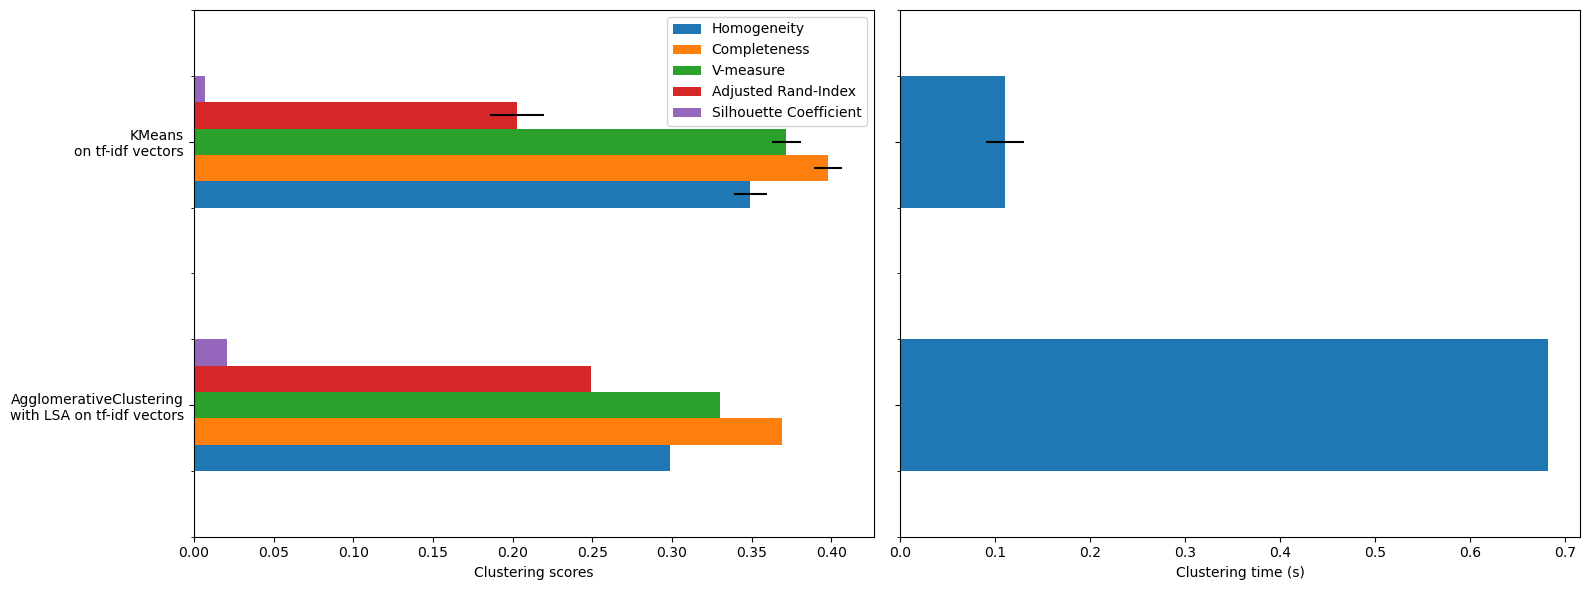

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(16, 6), sharey=True)

df = pd.DataFrame(evaluations[::-1]).set_index("estimator")
df_std = pd.DataFrame(evaluations_std[::-1]).set_index("estimator")

df.drop(
    ["train_time"],
    axis="columns",
).plot.barh(ax=ax0, xerr=df_std)
ax0.set_xlabel("Clustering scores")
ax0.set_ylabel("")

df["train_time"].plot.barh(ax=ax1, xerr=df_std["train_time"])
ax1.set_xlabel("Clustering time (s)")
plt.tight_layout()

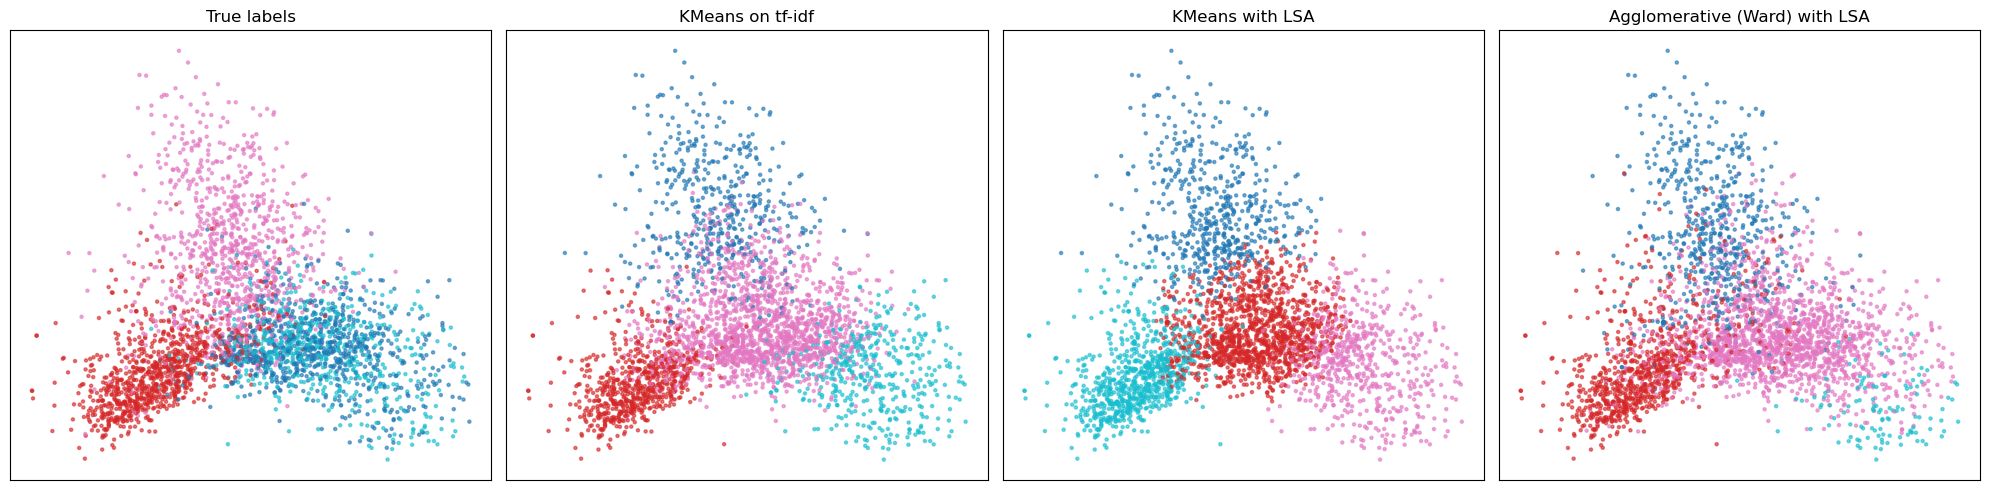

In [10]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

# Projection en 2D (la même pour tous les graphiques)
X_2d = PCA(n_components=2, random_state=0).fit_transform(X_lsa)

configurations = {
    "True labels": labels,
    "KMeans on tf-idf": KMeans(
        n_clusters=true_k, max_iter=100, n_init=1, random_state=0
    ).fit(X_tfidf).labels_,
    "KMeans with LSA": KMeans(
        n_clusters=true_k, max_iter=100, n_init=1, random_state=0
    ).fit(X_lsa).labels_,
    "Agglomerative (Ward) with LSA": AgglomerativeClustering(
        n_clusters=true_k, linkage="ward"
    ).fit(X_lsa).labels_,
}

fig, axes = plt.subplots(1, len(configurations), figsize=(5 * len(configurations), 5))
for ax, (name, cluster_labels) in zip(axes, configurations.items()):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels, cmap="tab10", s=5, alpha=0.6)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

In [11]:
True labels : sur cette figure, nous observons 4 couleurs qui représentent les 4 vraies catégories : rouge = graphisme, rose = espace, bleu foncé = athéisme, bleu clair = religion. Les points forment un triangle. Le rouge et le rose forment des groupes nets, mais le bleu clair et le bleu foncé se mélangent, car ces deux catégories parlent de religion avec le même vocabulaire.

KMeans on tf-idf : l’algorithme retrouve bien le groupe en bas à gauche (graphisme) et le groupe du haut (espace), mais il crée un groupe au milieu qui mélange plusieurs catégories.

KMeans with LSA : cette figure est la plus différente de la réalité : l’algorithme coupe le groupe du graphisme en deux, et il réunit les deux catégories sur la religion dans un seul groupe.

Agglomerative (Ward) : cette figure est la plus proche de la première : on retrouve le graphisme en bas à gauche, l’espace en haut et la religion à droite. Le quatrième groupe est très petit.




les couleurs des figures de clustering sont données au hasard par l’algorithme, il faut donc comparer la place des groupes et non les couleurs. Toutes les méthodes retrouvent bien le graphisme et l’espace, mais aucune n’arrive à séparer l’athéisme et la religion, car ces textes se ressemblent trop.